Begin Our PySpark Session.

In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder.appName("Data Cleaning Curated 2")
    .config("spark.sql.repl.eagerEval.enabled", True)
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config('spark.driver.memory', '8g')
    .config('spark.executor.memory', '4g')
    .getOrCreate()
)
# Silence any WARN-level logs from this point forth.
spark.sparkContext.setLogLevel("ERROR")

In [3]:
from functools import reduce

def null_check(df):
    has_null_condition = reduce(
        lambda acc, c: acc | F.col(c).isNull(),
        df.columns,
        F.lit(False)
    )

    # Count total rows, rows with atleast one null and count how many nulls occur per
    # data field.
    summary = df.agg(
        F.count(F.lit(1)).alias("total_rows"),
        F.sum(has_null_condition.cast("int")).alias("rows_with_at_least_one_null"),
        *[F.sum(F.col(c).isNull().cast("int")).alias(f"null_{c}") for c in df.columns]
    ).collect()[0]
    
    total = summary["total_rows"]
    rows_with_at_least_one_null = summary["rows_with_at_least_one_null"]
    
    print(f"Total rows: {total:,}")
    print(f"Rows with at least one null value: {rows_with_at_least_one_null:,}")
    print(f"Percentage of rows with atleast one NULL: {round(100 * rows_with_at_least_one_null / total, 2)}%")
    print()
    for c in df.columns:
        print(f"{c:25s} {summary[f'null_{c}']:>12,}")

<br>
<br>
<br>

### Dealing with Non-Residential Buildings

In [24]:
curated_one_path = "../../rea_data/curated/vic_rentals_curated_1.parquet"

df_curated_one = spark.read.parquet(curated_one_path)

The assignment brief asks us to predict rents for residential properties and apartments, and to find liveable, affordable suburbs. Things like a car space, Vacant land *etc.* isn't somewhere anyone lives, so it doesn't belong in those answers. 

So we should investigate the different `property_type`'s that appear in this data set and remove those that are irrelevant.

In [25]:
# What property types are in the data 
df_curated_one.groupBy("property_type").agg(
    F.count("*").alias("n"),
).orderBy(F.desc("n")).show(50, truncate=False)

+-----------------------------+----+
|property_type                |n   |
+-----------------------------+----+
|House                        |6589|
|Apartment / Unit / Flat      |4516|
|Townhouse                    |1278|
|Studio                       |209 |
|New Apartments / Off the Plan|45  |
|Villa                        |28  |
|Acreage / Semi-Rural         |13  |
|Semi-Detached                |10  |
|New House & Land             |8   |
|Car Space                    |7   |
|Block of Units               |3   |
|Terrace                      |3   |
|Duplex                       |3   |
|Farm                         |2   |
|Unknown                      |2   |
|Vacant land                  |1   |
+-----------------------------+----+



So, only Car Space (7), Vacant land (1) and Unknown (2) need to go. Everything else is somewhere people can live.

In [26]:
non_residential_types = ["Car Space", "Vacant land", "Unknown"]

n_before = df_curated_one.count()

non_res = df_curated_one.filter(F.col("property_type").isin(non_residential_types))
print(f"Non-residential listings removed: {non_res.count():,}")


df_curated_one = df_curated_one.filter(~F.col("property_type").isin(non_residential_types)).cache()
print(f"Remaining: {df_curated_one.count():,} "f"({round(100 * non_res.count() / n_before, 2)}%)")

Non-residential listings removed: 10
Remaining: 12,707 (0.08%)


<br>
<br>
<br>

### Dealing with `weekly_rent` 

Seeing as though `weekly_rent` is our **response variable** (the variable we wish to predict), we must ensure that it contains valid values. Since this is the variable we are trying to predict, missing or invalid values cannot be imputed and should instead be removed.


In [27]:
null_check(df_curated_one)

Total rows: 12,707
Rows with at least one null value: 12,707
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                        276
bond                               781
available_date                     135
date_listed                          4
days_listed                          4
bedrooms                           119
bathrooms                           45
carspaces                        1,800
property_type                        0
address                            104
lat                                  4
lon                                  4
scraped_date                         0
domain_page_id                       1
property_id                     10,139
photo_count                          4
video_count                          4
floorplans_count                     4
virtual_tour                         4
primary_type                   

Firstly, evident by the previous cell's `null_check`, lets remove all 276 rows where `weekly_rent` is `NULL`

In [28]:
# Drop listings with no weekly_rent (null values)
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.col("weekly_rent").isNotNull())

n_after = df_curated_one.count()
print(f"Rows before: {n_before:,}")
print(f"Rows after:  {n_after:,}")
print(f"Dropped {n_before - n_after:,} listings with NULL weekly_rent "
      f"({round(100 * (n_before - n_after) / n_before, 2)}%)")

Rows before: 12,707
Rows after:  12,431
Dropped 276 listings with NULL weekly_rent (2.17%)


Furthermore, lets do an analysis on `weekly_rent` values to see which values are plausabile and which are not. This could be as a result of misinputs, bad parsing *etc.*

In [29]:
df_curated_one.agg(
    F.min("weekly_rent").alias("min"),
    F.round(F.mean("weekly_rent"), 2).alias("mean"),
    F.max("weekly_rent").alias("max"),
).show()

+---+-----+--------+
|min| mean|     max|
+---+-----+--------+
|0.0|765.1|808500.0|
+---+-----+--------+



In [30]:
print("=== Top 10 highest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.desc("weekly_rent")).show(10)

print("=== Top 10 lowest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.asc("weekly_rent")).show(10)

=== Top 10 highest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17697966|   808500.0|
|  17750082|   595000.0|
|  17747509|   315000.0|
|  17712191|    10000.0|
|  17661725|     5866.0|
|  17722803|     5750.0|
|   9287841|     5000.0|
|  17744678|     4500.0|
|  17694334|     4500.0|
|  17460975|     4000.0|
+----------+-----------+
only showing top 10 rows
=== Top 10 lowest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17175722|        0.0|
|  17316329|        0.0|
|  17442602|        0.0|
|  17159699|        0.0|
|  10344261|        0.0|
|  17456126|        0.0|
|  16697431|        0.0|
|  16706257|        0.0|
|  17416575|        0.0|
|  15367349|        0.0|
+----------+-----------+
only showing top 10 rows


First and foremost, its easy to see that the 3 highest weekly rents are most certainly incorrect; most likely the price of the given house/apartment rather than the `weekly_rent`, so we should remove these accordingly. Likewise, any `weekly_rent` that is $=0$ (for whatever reason it may be) is certainly invalid and should also be removed.

Note: As shown by this web page, https://www.domain.com.au/toorak-vic-3142-17712191, the listing with a `weekly_rent` of \$10,000 was found to be a legitimate price.

And so we proceed with said filtering in the following cell:

In [31]:
# --- Remove confirmed misparsed rents (sale prices / concatenated digits) and $0 placeholders ---
misparsed_ids = [17697966, 17750082, 17747509]   # $808,500 / $595,000 / $315,000

n_before = df_curated_one.count()

n_misparsed = df_curated_one.filter(F.col("listing_id").isin(misparsed_ids)).count()
n_zero = df_curated_one.filter(F.col("weekly_rent") == 0).count()

df_curated_one = df_curated_one.filter(
    ~F.col("listing_id").isin(misparsed_ids) & (F.col("weekly_rent") > 0)
)

n_after = df_curated_one.count()
print(f"Removed {n_misparsed} unreasonably high rents")
print(f"Removed {n_zero} listings with weekly_rent = 0")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 3 unreasonably high rents
Removed 17 listings with weekly_rent = 0
Rows: 12,431 -> 12,411


In [32]:
df_curated_one.agg(
    F.min("weekly_rent").alias("min"),
    F.round(F.mean("weekly_rent"), 2).alias("mean"),
    F.max("weekly_rent").alias("max"),
).show()

print("=== Top 10 highest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.desc("weekly_rent")).show(10)

print("=== Top 10 lowest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.asc("weekly_rent")).show(10)

+----+------+-------+
| min|  mean|    max|
+----+------+-------+
|18.0|627.87|10000.0|
+----+------+-------+

=== Top 10 highest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17712191|    10000.0|
|  17661725|     5866.0|
|  17722803|     5750.0|
|   9287841|     5000.0|
|  17694334|     4500.0|
|  17744678|     4500.0|
|  17460975|     4000.0|
|  17750966|     4000.0|
|  14253235|     3900.0|
|  17721041|     3850.0|
+----------+-----------+
only showing top 10 rows
=== Top 10 lowest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  13243113|       18.0|
|  12352715|       22.0|
|  16490695|       27.0|
|  12981625|       30.0|
|  12981632|       30.0|
|  16559047|       33.0|
|  10801345|       33.0|
|  12853814|       36.0|
|  17240713|       42.0|
|  16211673|       46.0|
+----------+-----------+
only showing top 10 rows


#### Outlier treatment for `weekly_rent`

Lets now flag outliers using IQR fences on log(weekly_rent), with a multiplier that grows
with sample size, k = √(ln N) − 0.5. With N = 12,411
this gives k = 2.57. On the log scale the distribution is roughly symmetric.

- **Lower fence: $203/week** 86 listings flagged.
  
- **Upper fence: $1,663/week** 137 listings flagged.

**We treat the two tails differently.**

*Low outliers (removed).* Rents below about $200/week are implausible for a
self-contained residential lease in Victoria from our outlier analysis.

*High outliers (kept).* High rents are a genuine part of the Victorian rental market,
not data errors. The flagged listings are concentrated in premium suburbs such as
[Toorak, Brighton, South Yarra, …]. They are mostly large houses
and their bonds are consistent with the advertised rent.
Removing the remaining high-end listings would:

1. Understate rents in premium suburbs, where the model would have little data to learn from.
2. Distort the feature-importance question, since features associated with luxury
   properties (pools, tennis courts, city views) would be underrepresented.
3. Bias the growth-rate and affordability analysis, which should cover the full
   market, not a truncated version of it.

Modelling log(weekly_rent) also reduces the influence of these high values on the
fit, so keeping them does not let a few listings dominate the model.

In [33]:
import math

# --- IQR fences with a sample-size-adjusted multiplier ---
df_iqr = df_curated_one.withColumn("log_rent", F.log("weekly_rent"))

N = df_iqr.count()
k = math.sqrt(math.log(N)) - 0.5

q1, q3 = df_iqr.approxQuantile("log_rent", [0.25, 0.75], 0.0)
iqr = q3 - q1
lower_fence = q1 - k * iqr
upper_fence = q3 + k * iqr

print(f"N = {N:,}")
print(f"k = sqrt(ln N) - 0.5 = {k:.3f}")
print(f"Q1 = ${math.exp(q1):,.0f}, Q3 = ${math.exp(q3):,.0f}")
print(f"Lower fence = ${math.exp(lower_fence):,.0f} / week")
print(f"Upper fence = ${math.exp(upper_fence):,.0f} / week")

df_iqr = df_iqr.withColumn(
    "iqr_flag",
    F.when(F.col("log_rent") < lower_fence, F.lit("low_outlier"))
     .when(F.col("log_rent") > upper_fence, F.lit("high_outlier"))
     .otherwise(F.lit("ok"))
)

df_iqr.groupBy("iqr_flag").count().show()

N = 12,411
k = sqrt(ln N) - 0.5 = 2.570
Q1 = $490, Q3 = $690
Lower fence = $203 / week
Upper fence = $1,663 / week
+------------+-----+
|    iqr_flag|count|
+------------+-----+
|high_outlier|  137|
|          ok|12188|
| low_outlier|   86|
+------------+-----+



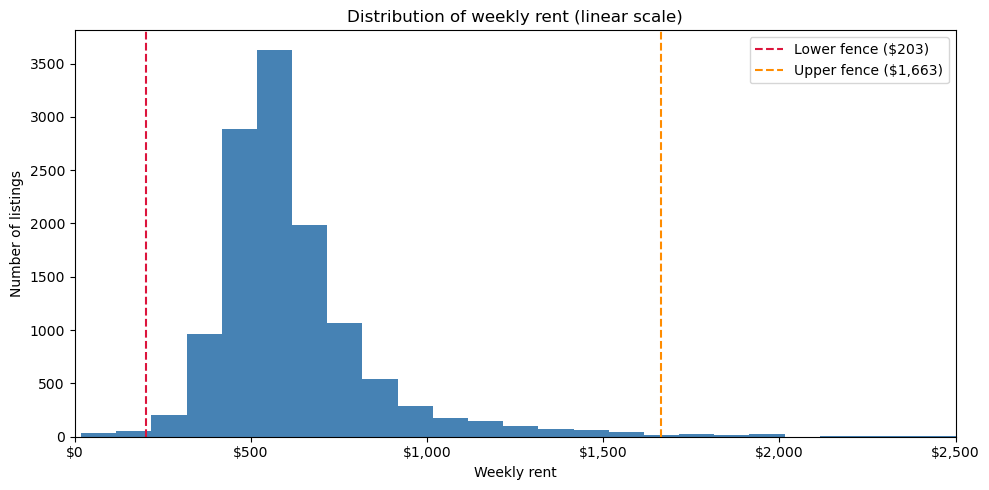

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

rent = df_iqr.select("weekly_rent").toPandas()["weekly_rent"]

# Fences were computed in log space (Cell 1) — convert back to dollars
lower_fence_dollar = math.exp(lower_fence)
upper_fence_dollar = math.exp(upper_fence)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(rent, bins=100, color="steelblue", edgecolor="none")

ax.axvline(lower_fence_dollar, color="crimson", ls="--", lw=1.5,
           label=f"Lower fence (${lower_fence_dollar:,.0f})")
ax.axvline(upper_fence_dollar, color="darkorange", ls="--", lw=1.5,
           label=f"Upper fence (${upper_fence_dollar:,.0f})")

ax.set_xlim(0, 2500)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))

ax.set_title("Distribution of weekly rent (linear scale)")
ax.set_xlabel("Weekly rent")
ax.set_ylabel("Number of listings")
ax.legend()
plt.tight_layout()
plt.show()

In [37]:
import math

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

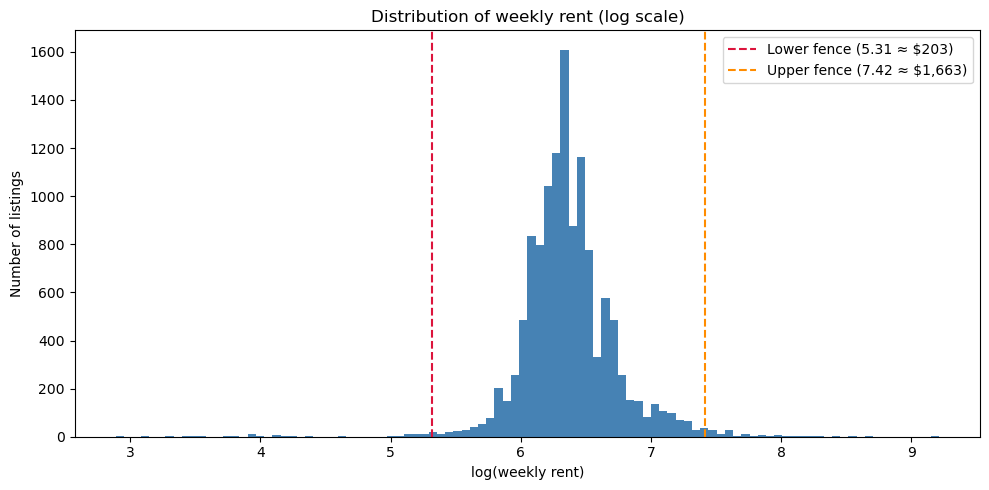

In [38]:
log_rent = np.log(rent)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(log_rent, bins=100, color="steelblue", edgecolor="none")

# Fences are already in log space, so plot them as they are.
ax.axvline(lower_fence, color="crimson", ls="--", lw=1.5,
           label=f"Lower fence ({lower_fence:.2f} ≈ "
                 f"${lower_fence_dollar:,.0f})")
ax.axvline(upper_fence, color="darkorange", ls="--", lw=1.5,
           label=f"Upper fence ({upper_fence:.2f} ≈ "
                 f"${upper_fence_dollar:,.0f})")

ax.set_title("Distribution of weekly rent (log scale)")
ax.set_xlabel("log(weekly rent)")
ax.set_ylabel("Number of listings")
ax.legend()
plt.tight_layout()
plt.show()

In [39]:
review_cols = ["listing_id", "suburb", "primary_type", "bedrooms", "weekly_rent", "url"]

print("=== Low outliers ===")
df_iqr.filter(F.col("iqr_flag") == "low_outlier").select(review_cols) \
    .orderBy("weekly_rent").show(100, vertical=True, truncate=False)

print("=== High outliers ===")
df_iqr.filter(F.col("iqr_flag") == "high_outlier").select(review_cols) \
    .orderBy(F.desc("weekly_rent")).show(100, vertical=True, truncate=False)

=== Low outliers ===
-RECORD 0---------------------------------------------------------------------------------------------------
 listing_id   | 13243113                                                                                    
 suburb       | TONGALA                                                                                     
 primary_type | House                                                                                       
 bedrooms     | NULL                                                                                        
 weekly_rent  | 18.0                                                                                        
 url          | https://www.domain.com.au/5-greiner-court-tongala-vic-3621-13243113                         
-RECORD 1---------------------------------------------------------------------------------------------------
 listing_id   | 12352715                                                                                   

And so, let us **remove** the 86 low end outliers now.

In [40]:
# Remove low-end rent outliers (below the lower IQR fence)
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.log("weekly_rent") >= lower_fence)

n_after = df_curated_one.count()
print(f"Removed {n_before - n_after} low-end outliers "
      f"(weekly_rent < ${math.exp(lower_fence):,.0f}/week)")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 86 low-end outliers (weekly_rent < $203/week)
Rows: 12,411 -> 12,325


Furthermore, lets manually investigate particularly high outlier `weekly_rent` values to ensure they are legitimate.

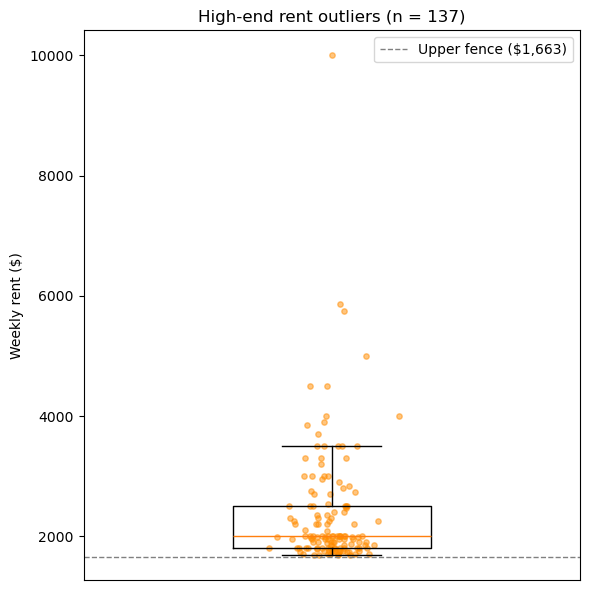

In [41]:
import numpy as np
import matplotlib.pyplot as plt

high_rents = df_iqr.filter(F.col("iqr_flag") == "high_outlier") \
    .select("weekly_rent").toPandas()["weekly_rent"]

fig, ax = plt.subplots(figsize=(6, 6))

ax.boxplot(high_rents, vert=True, widths=0.4, showfliers=False)

# Each listing as a jittered dot, so you can see how they spread
jitter = np.random.normal(1, 0.04, size=len(high_rents))
ax.scatter(jitter, high_rents, alpha=0.5, s=15, color="darkorange")

ax.axhline(np.exp(upper_fence), color="grey", ls="--", lw=1,
           label=f"Upper fence (${np.exp(upper_fence):,.0f})")

ax.set_title(f"High-end rent outliers (n = {len(high_rents)})")
ax.set_ylabel("Weekly rent ($)")
ax.set_xticks([])
ax.legend()
plt.tight_layout()
plt.show()

In [42]:
high_pdf = df_iqr.filter(F.col("iqr_flag") == "high_outlier") \
    .select("listing_id", "suburb", "primary_type", "bedrooms",
            "weekly_rent", "bond", "url").toPandas()

q1_h, q3_h = high_pdf["weekly_rent"].quantile([0.25, 0.75])
whisker = q3_h + 1.5 * (q3_h - q1_h)

above = high_pdf[high_pdf["weekly_rent"] > whisker] \
    .sort_values("weekly_rent", ascending=False)

print(f"Upper whisker within high outliers: ${whisker:,.0f}/week")
print(f"Listings above it: {len(above)}")
above

Upper whisker within high outliers: $3,550/week
Listings above it: 11


,listing_id,suburb,primary_type,bedrooms,weekly_rent,bond,url
87,17712191,TOORAK,House,6.0,10000.0,60000.0,https://www.domain.com.au/toorak-vic-3142-1771...
113,17661725,CAMBERWELL,House,5.0,5866.0,5866.0,https://www.domain.com.au/54-fairmont-avenue-c...
88,17722803,TOORAK,House,4.0,5750.0,34500.0,https://www.domain.com.au/2-lisbuoy-court-toor...
129,9287841,BRIGHTON,Apartment,5.0,5000.0,NaN,https://www.domain.com.au/brighton-vic-3186-92...
67,17744678,HAWTHORN,House,5.0,4500.0,27000.0,https://www.domain.com.au/94-illawarra-road-ha...
99,17694334,SOUTH YARRA,Apartment,3.0,4500.0,27000.0,https://www.domain.com.au/1-fairlie-court-sout...
5,17460975,SOUTH MELBOURNE,Apartment,4.0,4000.0,24000.0,https://www.domain.com.au/901-161-eastern-road...
119,17750966,BRIGHTON,House,4.0,4000.0,24000.0,https://www.domain.com.au/74-champion-street-b...
9,14253235,PORT MELBOURNE,Townhouse/Villa,4.0,3900.0,23400.0,https://www.domain.com.au/1-tarver-st-port-mel...
26,17721041,CREMORNE,House,4.0,3850.0,15400.0,https://www.domain.com.au/13-balmain-st-cremor...


Upon our manual inspection of every high-end listing above the box-plot whisker (done by serching the property listing online), we find that `listing_id` = 17661725 is the only listing that has a false `weekly_rent` value. Since its true `weekly_rent` cannon't reliably be infered we will remove this row aswell.

In [43]:
# --- Remove a high-end listing confirmed as misparsed after manual review ---
n_before = df_curated_one.count()

HIGH_END_LISTING_FALSE = 17661725

df_curated_one = df_curated_one.filter(F.col("listing_id") != HIGH_END_LISTING_FALSE)

print(f"Removed {n_before - df_curated_one.count()} listing (listing_id = 17661725)")
print(f"Rows: {n_before:,} -> {df_curated_one.count():,}")

Removed 1 listing (listing_id = 17661725)
Rows: 12,325 -> 12,324


Lets persist what we have done for `weekly_values` and Non-Residential buildings for ease of use for further data cleaning.

In [44]:
# Save the cleaned DataFrame to Parquet format
output_path = "../../rea_data/curated/vic_rentals_curated_2.parquet"

df_curated_one.write.mode("overwrite").parquet(output_path)

print(f"Shape: {df_curated_one.count():,} rows, {len(df_curated_one.columns)} columns")

Shape: 12,324 rows, 84 columns


<br>
<br>
<br>

### Dealing with `date_listed`

In [45]:
curated_two_path = "../../rea_data/curated/vic_rentals_curated_2.parquet"

df_curated_two = spark.read.parquet(curated_two_path)

`date_listed` is very obviously important to our project so lets clean this column for missing or invalid values.

Lets begin by checking for any `NULL` values.

In [46]:
null_check(df_curated_two)

Total rows: 12,324
Rows with at least one null value: 12,324
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                          0
bond                               738
available_date                       4
date_listed                          4
days_listed                          4
bedrooms                            76
bathrooms                            8
carspaces                        1,704
property_type                        0
address                             87
lat                                  4
lon                                  4
scraped_date                         0
domain_page_id                       1
property_id                     10,006
photo_count                          4
video_count                          4
floorplans_count                     4
virtual_tour                         4
primary_type                   

There are 4 values where `date_listed` = `NULL` so lets remove these.

In [48]:
# Drop listings with no date_listed 
n_before = df_curated_two.count()

df_curated_two = df_curated_two.filter(F.col("date_listed").isNotNull())

n_after = df_curated_two.count()
print(f"Removed {n_before - n_after} listings with NULL date_listed")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 4 listings with NULL date_listed
Rows: 12,324 -> 12,320


Now lets check that all non-null `date_listed` values parse as valid dates (`yyyy-MM-dd`).

The older listings will be kept for time-series modelling.

In [49]:
df_curated_two.select(
    F.sum(
        (F.col("date_listed").isNotNull() &
         F.to_date(F.col("date_listed").cast("string"), "yyyy-MM-dd").isNull()).cast("int")
    ).alias("unparseable"),
    F.min("date_listed").alias("earliest"),
    F.max("date_listed").alias("latest"),
).show()

+-----------+----------+----------+
|unparseable|  earliest|    latest|
+-----------+----------+----------+
|          0|2012-06-09|2025-09-09|
+-----------+----------+----------+



All non-null `date_listed` values parse as valid dates (`yyyy-MM-dd`), ranging from 9 June 2012 to 9 September 2025, the scrape date, so no values are malformed or in the future.

Since we hope to create a time series model with our data, lets feature engineer a `listed_month` and `listed_year` column to indicate, obviously, what month and year a property was listed.

In [50]:
# Extract year and month from date_listed 
df_curated_two = (
    df_curated_two
    .withColumn("date_listed", F.to_date("date_listed"))
    .withColumn("listed_year", F.year("date_listed"))
    .withColumn("listed_month", F.month("date_listed"))
)

df_curated_two.select("date_listed", "listed_year", "listed_month").show(1, vertical=True)

-RECORD 0------------------
 date_listed  | 2025-08-13 
 listed_year  | 2025       
 listed_month | 8          
only showing top 1 row


<br>
<br>
<br>

### Dealing with `bedrooms`, `bathrooms` and `carspaces`

We hope to investigate the relevance of these categories in further modelling so lets clean them as necessary.

As usual, lets check for any `NULL` values

In [52]:
null_check(df_curated_two)

Total rows: 12,320
Rows with at least one null value: 12,320
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                          0
bond                               734
available_date                       0
date_listed                          0
days_listed                          0
bedrooms                            76
bathrooms                            8
carspaces                        1,704
property_type                        0
address                             86
lat                                  3
lon                                  3
scraped_date                         0
domain_page_id                       0
property_id                     10,002
photo_count                          0
video_count                          0
floorplans_count                     0
virtual_tour                         0
primary_type                   

Since these listings weren't found to have data collection issues (properties were 
manually checked against their original listings), the missingness is likely **Missing 
Not At Random (MNAR)** rather than a random data quality problem. 

Let's test this by checking whether missing `bedrooms` values cluster within 
specific `property_type` categories, compared to that type's overall share of the dataset.

In [53]:
# --- Does missingness cluster in certain property types? ---
print("=== property_type breakdown: missing bedrooms ===")
df_curated_two.filter(F.col("bedrooms").isNull()) \
    .groupBy("property_type").count().orderBy(F.desc("count")).show(truncate=False)

print("=== For comparison: overall property_type distribution ===")
df_curated_two.groupBy("property_type").count().orderBy(F.desc("count")).show(truncate=False)

=== property_type breakdown: missing bedrooms ===
+-----------------------+-----+
|property_type          |count|
+-----------------------+-----+
|Studio                 |46   |
|Apartment / Unit / Flat|25   |
|House                  |4    |
|Farm                   |1    |
+-----------------------+-----+

=== For comparison: overall property_type distribution ===
+-----------------------------+-----+
|property_type                |count|
+-----------------------------+-----+
|House                        |6352 |
|Apartment / Unit / Flat      |4416 |
|Townhouse                    |1251 |
|Studio                       |192  |
|New Apartments / Off the Plan|44   |
|Villa                        |26   |
|Acreage / Semi-Rural         |11   |
|Semi-Detached                |10   |
|New House & Land             |7    |
|Block of Units               |3    |
|Terrace                      |3    |
|Duplex                       |3    |
|Farm                         |2    |
+-------------------------

As further evidence, let's compare `weekly_rent` and `land_area_sqm` between listings 
with and without missing `bedrooms`. If the missing group skews towards smaller, cheaper 
properties, that supports the theory that these are structurally simple listings 
(e.g. studios) rather than random gaps in the data.

In [54]:
df_curated_two.withColumn(
    "bedrooms_missing", F.col("bedrooms").isNull()
).groupBy("bedrooms_missing").agg(
    F.round(F.mean("weekly_rent"), 2).alias("mean_rent"),
    F.round(F.mean("land_area_sqm"), 2).alias("mean_land_area"),
    F.count("*").alias("n")
).show()

+----------------+---------+--------------+-----+
|bedrooms_missing|mean_rent|mean_land_area|    n|
+----------------+---------+--------------+-----+
|            true|   447.28|          NULL|   76|
|           false|   632.04|         359.5|12244|
+----------------+---------+--------------+-----+



#### Studio listings: impute 0

`Studio` listings account for a disproportionate share of missing `bedrooms` (46 of 192 
Studios, vs <1% missingness elsewhere). This fits: a studio has no separate bedroom by 
definition, so the field is often left blank rather than recorded as `0`. This is 
**structural imputation**, not statistical — the value is 0 because it must be, not 
because it's the average.

In [55]:
# --- Structural imputation: Studios have 0 separate bedrooms by definition ---
df_curated_two = df_curated_two.withColumn(
    "bedrooms",
    F.when(
        (F.col("bedrooms").isNull()) & (F.col("property_type") == "Studio"),
        F.lit(0)
    ).otherwise(F.col("bedrooms"))
)

The remaining missing `bedrooms` (Apartment/Unit/Flat, House, Farm) don't have the same 
structural justification as Studios. Let's manually inspect each listing's original page 
(via `url`) to determine, case by case, whether the bedroom count was:

- genuinely visible on the listing but not captured during scraping, 
- structurally absent (e.g. an apartment with no separate bedroom), or
- a normal but unrecorded value (e.g. a house).

In [56]:
# --- Look closer at non-Studio missing bedrooms ---
df_curated_two.filter(
    F.col("bedrooms").isNull() & (F.col("property_type") != "Studio")
).select("listing_id", "property_type", "primary_type", "weekly_rent", "land_area_sqm", "suburb", "url") \
 .show(30, truncate=False, vertical=True)

-RECORD 0------------------------------------------------------------------------------------------------
 listing_id    | 17747629                                                                                
 property_type | Apartment / Unit / Flat                                                                 
 primary_type  | Apartment                                                                               
 weekly_rent   | 569.0                                                                                   
 land_area_sqm | NULL                                                                                    
 suburb        | SOUTH MELBOURNE                                                                         
 url           | https://www.domain.com.au/studios-15-85-gladstone-st-south-melbourne-vic-3205-17747629  
-RECORD 1------------------------------------------------------------------------------------------------
 listing_id    | 17371355                     

#### Manually verified corrections

Upon inspecting each listing's original page, 5 properties had a clearly stated bedroom 
count that was simply missed during scraping. These are corrected directly from the 
verified source rather than imputed.

In [57]:
# --- Manual correction: bedrooms visible on listing, just not captured in scrape ---
manual_bedroom_fixes = {
    17268383: 1,   # replace with actual listing_id : bedrooms
    17725025: 2,
    17442573: 1,
    17341506: 1, 
    17753043: 4                                                                                                                                                                                                                                                                                      , 
}

fix_expr = F.create_map([F.lit(x) for pair in manual_bedroom_fixes.items() for x in pair])

df_curated_two = df_curated_two.withColumn(
    "bedrooms",
    F.when(
        F.col("bedrooms").isNull() & F.col("listing_id").isin(list(manual_bedroom_fixes.keys())),
        fix_expr[F.col("listing_id")]
    ).otherwise(F.col("bedrooms"))
)

print(f"Manually corrected {len(manual_bedroom_fixes)} listings")

Manually corrected 5 listings


#### Apartment / Unit / Flat: impute 0

For the remaining missing Apartment/Unit/Flat listings, manual inspection showed the 
majority did not have a separate bedroom (open-plan/common living space instead). As with 
Studios, this is treated as a structural 0 rather than statistically imputed.

In [58]:
# --- Structural imputation: studio-style apartments have no separate bedroom ---
df_curated_two = df_curated_two.withColumn(
    "bedrooms",
    F.when(
        F.col("bedrooms").isNull() & (F.col("property_type") == "Apartment / Unit / Flat"),
        F.lit(0)
    ).otherwise(F.col("bedrooms"))
)

#### Houses: impute median

Unlike Studios and Apartments, missing House listings showed a normal bedroom count on 
manual inspection (2+ bedrooms) — there's no structural reason for these to be 0. Since 
there's no evidence the value is degenerate, we impute the median `bedrooms` for Houses, 
which is appropriate here given the small number of affected rows and lack of a better 
signal.

In [59]:
# --- Median imputation for Houses (normal distribution, no structural reason for 0) ---
house_median_bedrooms = df_curated_two.filter(
    (F.col("property_type") == "House") & F.col("bedrooms").isNotNull()
).approxQuantile("bedrooms", [0.5], 0.0)[0]

print(f"House median bedrooms: {house_median_bedrooms}")

df_curated_two = df_curated_two.withColumn(
    "bedrooms",
    F.when(
        F.col("bedrooms").isNull() & (F.col("property_type") == "House"),
        F.lit(house_median_bedrooms)
    ).otherwise(F.col("bedrooms"))
)

House median bedrooms: 3.0


#### Farm: impute 0

The single missing Farm listing was manually reviewed and no bedroom was visible in the 
listing photos or description, so it's treated as a structural 0 in line with the Studio 
and Apartment reasoning above.

In [60]:
# --- Impute 0 bedrooms for Farm listings (no bedroom visible on manual review) ---
df_curated_two = df_curated_two.withColumn(
    "bedrooms",
    F.when(
        F.col("bedrooms").isNull() & (F.col("property_type") == "Farm"),
        F.lit(0)
    ).otherwise(F.col("bedrooms"))
)

print(f"Remaining NULL bedrooms: {df_curated_two.filter(F.col('bedrooms').isNull()).count()}")

Remaining NULL bedrooms: 0


#### Final check: confirm all `bedrooms` values resolved

Let's confirm no `NULL` values remain across any `property_type`, to make sure every 
imputation branch was applied correctly and no listings slipped through.

In [61]:
# --- Final confirmation: bedrooms fully resolved across all property types ---
df_curated_two.filter(F.col("bedrooms").isNull()) \
    .groupBy("property_type").count().show(truncate=False)

print(f"Total remaining NULL bedrooms: {df_curated_two.filter(F.col('bedrooms').isNull()).count()}")

+-------------+-----+
|property_type|count|
+-------------+-----+
+-------------+-----+

Total remaining NULL bedrooms: 0


### Dealing with missing `bathrooms`

As with `bedrooms`, let's pull the full records (including `url`) for every listing with 
a missing `bathrooms` value, so each one can be manually checked against its original 
listing page.

In [62]:
# --- Missing bathrooms: full records for manual review ---
df_curated_two.filter(F.col("bathrooms").isNull()) \
    .select("listing_id", "property_type", "primary_type", "weekly_rent", "land_area_sqm", "suburb", "url") \
    .show(df_curated_two.filter(F.col("bathrooms").isNull()).count(), truncate=False, vertical=True)

-RECORD 0--------------------------------------------------------------------------------------
 listing_id    | 17371355                                                                      
 property_type | Farm                                                                          
 primary_type  | Any                                                                           
 weekly_rent   | 1000.0                                                                        
 land_area_sqm | NULL                                                                          
 suburb        | LEMNOS                                                                        
 url           | https://www.domain.com.au/70-lemnos-north-road-lemnos-vic-3631-17371355       
-RECORD 1--------------------------------------------------------------------------------------
 listing_id    | 17696887                                                                      
 property_type | Apartment / Unit / Flat

#### Manually verified corrections

Upon inspecting each listing's original page, 3 of the 8 missing `bathrooms` values were 
clearly stated on the listing but simply missed during scraping. These are corrected 
directly from the verified source rather than imputed.

In [63]:
# --- Manual correction: bathrooms visible on listing, just not captured in scrape ---
manual_bathroom_fixes = {
    17725025: 2,   # replace with actual listing_id : bathrooms
    17744325: 1,
    17753043: 2,
}

fix_expr = F.create_map([F.lit(x) for pair in manual_bathroom_fixes.items() for x in pair])

df_curated_two = df_curated_two.withColumn(
    "bathrooms",
    F.when(
        F.col("bathrooms").isNull() & F.col("listing_id").isin(list(manual_bathroom_fixes.keys())),
        fix_expr[F.col("listing_id")]
    ).otherwise(F.col("bathrooms"))
)

print(f"Manually corrected {len(manual_bathroom_fixes)} listings")
print(f"Remaining NULL bathrooms: {df_curated_two.filter(F.col('bathrooms').isNull()).count()}")

Manually corrected 3 listings
Remaining NULL bathrooms: 5


#### MNAR analysis on the remaining missing bathrooms

With the 3 scrape-error listings now fixed, 5 genuinely missing `bathrooms` values 
remain. As with `bedrooms`, let's check whether this missingness clusters within specific 
`property_type` categories, compared to that type's overall share of the dataset.

In [64]:
# --- Does missingness cluster in certain property types? ---
print("=== property_type breakdown: missing bathrooms ===")
df_curated_two.filter(F.col("bathrooms").isNull()) \
    .groupBy("property_type").count().orderBy(F.desc("count")).show(truncate=False)

print("=== For comparison: overall property_type distribution ===")
df_curated_two.groupBy("property_type").count().orderBy(F.desc("count")).show(truncate=False)

=== property_type breakdown: missing bathrooms ===
+-----------------------+-----+
|property_type          |count|
+-----------------------+-----+
|Apartment / Unit / Flat|2    |
|House                  |2    |
|Farm                   |1    |
+-----------------------+-----+

=== For comparison: overall property_type distribution ===
+-----------------------------+-----+
|property_type                |count|
+-----------------------------+-----+
|House                        |6352 |
|Apartment / Unit / Flat      |4416 |
|Townhouse                    |1251 |
|Studio                       |192  |
|New Apartments / Off the Plan|44   |
|Villa                        |26   |
|Acreage / Semi-Rural         |11   |
|Semi-Detached                |10   |
|New House & Land             |7    |
|Block of Units               |3    |
|Terrace                      |3    |
|Duplex                       |3    |
|Farm                         |2    |
+-----------------------------+-----+



Let's also compare `weekly_rent` and `land_area_sqm` between listings with and without 
missing `bathrooms`, to check for the same kind of structural signal we saw with 
`bedrooms`.

In [65]:
# --- Compare weekly_rent and land_area_sqm: missing vs non-missing bathrooms ---
df_curated_two.withColumn(
    "bathrooms_missing", F.col("bathrooms").isNull()
).groupBy("bathrooms_missing").agg(
    F.round(F.mean("weekly_rent"), 2).alias("mean_rent"),
    F.round(F.mean("land_area_sqm"), 2).alias("mean_land_area"),
    F.count("*").alias("n")
).show()

+-----------------+---------+--------------+-----+
|bathrooms_missing|mean_rent|mean_land_area|    n|
+-----------------+---------+--------------+-----+
|             true|    633.0|          NULL|    5|
|            false|    630.9|         359.5|12315|
+-----------------+---------+--------------+-----+



Unlike `bedrooms`, the rent and land area comparison here shows no meaningful difference 
between the missing and non-missing groups — so there's no evidence of a structural zero 
across the board. Let's look at the individual records to see what's actually going on.

In [66]:
df_curated_two.filter(F.col("bathrooms").isNull()) \
    .select("listing_id", "property_type", "primary_type", "weekly_rent", "land_area_sqm", "suburb", "url") \
    .show(truncate=False, vertical=True)

-RECORD 0--------------------------------------------------------------------------------------
 listing_id    | 17371355                                                                      
 property_type | Farm                                                                          
 primary_type  | Any                                                                           
 weekly_rent   | 1000.0                                                                        
 land_area_sqm | NULL                                                                          
 suburb        | LEMNOS                                                                        
 url           | https://www.domain.com.au/70-lemnos-north-road-lemnos-vic-3631-17371355       
-RECORD 1--------------------------------------------------------------------------------------
 listing_id    | 17696887                                                                      
 property_type | Apartment / Unit / Flat

#### Apartment / Unit / Flat and House: impute median

Since rent and land area are near-identical between missing and non-missing listings, 
there's no structural reason to assume 0 bathrooms for these remaining rows. Unlike 
`bedrooms`, category-median imputation is appropriate here — the missingness within 
Apartment and House looks like an ordinary, non-structural gap.

The print statements below track NULL counts before/after each category to confirm every 
row is accounted for.

In [67]:
# --- Median imputation by property_type (excluding Farm) ---
non_farm_types = [
    row["property_type"] for row in
    df_curated_two.filter(
        F.col("bathrooms").isNull() & (F.col("property_type") != "Farm")
    ).select("property_type").distinct().collect()
]

print(f"property_types to impute: {non_farm_types}")
print(f"Total NULL bathrooms before loop: {df_curated_two.filter(F.col('bathrooms').isNull()).count()}")
print()

for ptype in non_farm_types:
    n_null_before = df_curated_two.filter(
        (F.col("property_type") == ptype) & F.col("bathrooms").isNull()
    ).count()

    median_bathrooms = df_curated_two.filter(
        (F.col("property_type") == ptype) & F.col("bathrooms").isNotNull()
    ).approxQuantile("bathrooms", [0.5], 0.0)[0]

    median_bathrooms = int(round(median_bathrooms))

    df_curated_two = df_curated_two.withColumn(
        "bathrooms",
        F.when(
            F.col("bathrooms").isNull() & (F.col("property_type") == ptype),
            F.lit(median_bathrooms)
        ).otherwise(F.col("bathrooms"))
    )

    n_null_after = df_curated_two.filter(
        (F.col("property_type") == ptype) & F.col("bathrooms").isNull()
    ).count()

    print(f"{ptype}:")
    print(f"  NULL before: {n_null_before}")
    print(f"  median bathrooms: {median_bathrooms}")
    print(f"  NULL after:  {n_null_after}")
    print(f"  rows imputed: {n_null_before - n_null_after}")
    print()

print(f"Total NULL bathrooms after loop: {df_curated_two.filter(F.col('bathrooms').isNull()).count()}")

property_types to impute: ['Apartment / Unit / Flat', 'House']
Total NULL bathrooms before loop: 5

Apartment / Unit / Flat:
  NULL before: 2
  median bathrooms: 1
  NULL after:  0
  rows imputed: 2

House:
  NULL before: 2
  median bathrooms: 2
  NULL after:  0
  rows imputed: 2

Total NULL bathrooms after loop: 1


#### Farm: impute 0

Unlike `bedrooms`, a farm's bathroom count isn't automatically structurally zero — a 
farm can have a dwelling with a bathroom. However, manual inspection of this listing's 
photos and description confirmed **there is no house or dwelling on the land**, meaning 
there's no bathroom to record. This is treated as a structural 0, but the reasoning is 
specific to this listing rather than the property type generally.

In [68]:
# --- Impute 0 bathrooms for Farm listing (manual inspection: no house/dwelling on land) ---
df_curated_two = df_curated_two.withColumn(
    "bathrooms",
    F.when(
        F.col("bathrooms").isNull() & (F.col("property_type") == "Farm"),
        F.lit(0)
    ).otherwise(F.col("bathrooms"))
)

print(f"Remaining NULL bathrooms: {df_curated_two.filter(F.col('bathrooms').isNull()).count()}")

Remaining NULL bathrooms: 0


<br>
<br>
<br>

### Dealing with Location

A key part of the analysis expected from this project is analysing how `weekly_rent` varies in regards to the `suburb`. So it is important that this column is cleaned for missing or invalid values.

Lets begin by observing if there are any `NULL` values present.

In [69]:
null_check(df_curated_two)

Total rows: 12,320
Rows with at least one null value: 12,320
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                          0
bond                               734
available_date                       0
date_listed                          0
days_listed                          0
bedrooms                             0
bathrooms                            0
carspaces                        1,704
property_type                        0
address                             86
lat                                  3
lon                                  3
scraped_date                         0
domain_page_id                       0
property_id                     10,002
photo_count                          0
video_count                          0
floorplans_count                     0
virtual_tour                         0
primary_type                   

There are no values for `suburb` or `postcode` that are missing which is good. Lets also check to see if there are any blank strings, which would avoid our `NULL` check.

In [70]:
df_curated_two.select(
    F.sum((F.trim("suburb") == "").cast("int")).alias("blank_suburb"),
    F.sum((F.trim("postcode") == "").cast("int")).alias("blank_postcode"),
).show()

+------------+--------------+
|blank_suburb|blank_postcode|
+------------+--------------+
|           0|             0|
+------------+--------------+



Victorian residential postcodes are 3000–3999 so lets ensure every `postcode` is indeed within **Victoria**.

In [71]:
df_curated_two.withColumn(
    "postcode_status",
    F.when(F.col("postcode").between(3000, 3999), "VIC residential")
     .otherwise("Outside VIC")
).groupBy("postcode_status").count().show(truncate=False)

+---------------+-----+
|postcode_status|count|
+---------------+-----+
|VIC residential|12320|
+---------------+-----+



Now lets also ensure `lat` and `long` values are fine since these are important for calculating useful distances.

From above, we see there are 3 rows with `lat` and `long` equal to `NULL`. Since it is only 3, its simplest to remove these rows.


In [72]:
# --- Drop listings with missing coordinates (can't be placed geographically) ---
n_before = df_curated_two.count()

df_curated_two = df_curated_two.filter(
    F.col("lat").isNotNull() & F.col("lon").isNotNull()
)

n_after = df_curated_two.count()
print(f"Removed {n_before - n_after} listings with NULL lat/lon")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 3 listings with NULL lat/lon
Rows: 12,320 -> 12,317


Lets ensure that coordinates of the listings remain within Victorias latitude and longitude bounds (dervided from https://www.ausstats.abs.gov.au/ausstats/free.nsf/0/64E1FDB5DA6720BFCA257FF5002214F9/$File/30_13012%20-Vic%20YrBook-1993_ABS_Geography.pdf with the help of ClaudeAI)

In [73]:
df_curated_two.select(
    F.min("lat").alias("min_lat"), F.max("lat").alias("max_lat"),
    F.min("lon").alias("min_lon"), F.max("lon").alias("max_lon"),
    F.sum((~F.col("lat").between(-39.2, -33.9) |
           ~F.col("lon").between(140.9, 150.0)).cast("int")).alias("outside_vic"),
).show()

+---------+---------+---------+---------+-----------+
|  min_lat|  max_lat|  min_lon|  max_lon|outside_vic|
+---------+---------+---------+---------+-----------+
|-38.82908|-34.16681|141.00055|149.75581|          0|
+---------+---------+---------+---------+-----------+



#### Dealing with `carspaces`
Check how much of `carspaces` is missing overall, before digging into *why*.

In [74]:
# --- Basic missingness check ---
n_missing_carspaces = df_curated_two.filter(F.col("carspaces").isNull()).count()
n_total = df_curated_two.count()

print(f"Missing carspaces: {n_missing_carspaces:,} / {n_total:,} "
      f"({round(100 * n_missing_carspaces / n_total, 2)}%)")


Missing carspaces: 1,704 / 12,317 (13.83%)


Break the missingness down by `property_type` to see if it's concentrated anywhere in particular.

In [75]:
print("=== property_type breakdown: missing carspaces ===")
df_curated_two.filter(F.col("carspaces").isNull()) \
    .groupBy("property_type").count().orderBy(F.desc("count")).show(truncate=False)

print("=== For comparison: overall property_type distribution ===")
df_curated_two.groupBy("property_type").count().orderBy(F.desc("count")).show(truncate=False)

=== property_type breakdown: missing carspaces ===
+-----------------------------+-----+
|property_type                |count|
+-----------------------------+-----+
|Apartment / Unit / Flat      |994  |
|House                        |483  |
|Studio                       |147  |
|New Apartments / Off the Plan|40   |
|Townhouse                    |28   |
|Semi-Detached                |3    |
|Block of Units               |2    |
|Terrace                      |2    |
|Acreage / Semi-Rural         |2    |
|Farm                         |1    |
|Villa                        |1    |
|New House & Land             |1    |
+-----------------------------+-----+

=== For comparison: overall property_type distribution ===
+-----------------------------+-----+
|property_type                |count|
+-----------------------------+-----+
|House                        |6349 |
|Apartment / Unit / Flat      |4416 |
|Townhouse                    |1251 |
|Studio                       |192  |
|New Apartments

Compare `weekly_rent`, `bedrooms`, `bathrooms`, and `days_listed` between missing and non-missing listings — a gap here would suggest the missingness isn't random.

In [76]:
df_curated_two.withColumn(
    "carspaces_missing", F.col("carspaces").isNull()
).groupBy("carspaces_missing").agg(
    F.round(F.mean("weekly_rent"), 2).alias("mean_rent"),
    F.round(F.mean("bedrooms"), 2).alias("mean_bedrooms"),
    F.round(F.mean("bathrooms"), 2).alias("mean_bathrooms"),
    F.round(F.mean("days_listed"), 2).alias("mean_days_listed"),
    F.count("*").alias("n")
).show()


+-----------------+---------+-------------+--------------+----------------+-----+
|carspaces_missing|mean_rent|mean_bedrooms|mean_bathrooms|mean_days_listed|    n|
+-----------------+---------+-------------+--------------+----------------+-----+
|             true|   576.91|         1.74|           1.2|          115.87| 1704|
|            false|   639.61|         2.88|          1.65|           47.93|10613|
+-----------------+---------+-------------+--------------+----------------+-----+



Check missing rate by suburb (n≥20 only, to avoid noise from tiny suburbs) — a strong inner-Melbourne skew would point toward a distance-to-CBD effect.

In [77]:
# Compare missing rate per suburb, to control for suburb size
suburb_missing_rate = df_curated_two.groupBy("suburb").agg(
    F.count("*").alias("total"),
    F.sum(F.col("carspaces").isNull().cast("int")).alias("missing")
).withColumn(
    "missing_rate", F.round(F.col("missing") / F.col("total"), 3)
).filter(F.col("total") >= 20)  # avoid noisy small-sample suburbs

print("=== Suburbs (n>=20) with highest carspaces missing rate ===")
suburb_missing_rate.orderBy(F.desc("missing_rate")).show(15, truncate=False)


=== Suburbs (n>=20) with highest carspaces missing rate ===
+---------------+-----+-------+------------+
|suburb         |total|missing|missing_rate|
+---------------+-----+-------+------------+
|MELBOURNE      |299  |228    |0.763       |
|CARLTON        |129  |85     |0.659       |
|KENSINGTON     |37   |23     |0.622       |
|SOUTHBANK      |300  |146    |0.487       |
|DOCKLANDS      |148  |67     |0.453       |
|BALACLAVA      |20   |9      |0.45        |
|FITZROY NORTH  |30   |12     |0.4         |
|CLAYTON        |150  |57     |0.38        |
|SOUTH MELBOURNE|100  |36     |0.36        |
|WEST MELBOURNE |75   |27     |0.36        |
|SOUTH YARRA    |207  |73     |0.353       |
|PRAHRAN        |86   |29     |0.337       |
|FOOTSCRAY      |159  |53     |0.333       |
|FITZROY        |28   |9      |0.321       |
|NORTH MELBOURNE|109  |35     |0.321       |
+---------------+-----+-------+------------+
only showing top 15 rows


### Distance to CBD
The suburb pattern above suggests missingness may track how central a listing is. Rather than relying on suburb names, compute an actual driving distance to the CBD using the OpenRouteService (ORS) Matrix API. This cell sets up the ORS credentials and CBD coordinates.

In [78]:
# --- ORS setup ---
import requests
import time

ORS_API_KEY = "***REMOVED***"
ORS_MATRIX_URL = "https://api.openrouteservice.org/v2/matrix/driving-car"

CBD_LON, CBD_LAT = 144.946457, -37.840935  # ORS uses [lon, lat] order

ORS's free tier caps requests at 500/day and 40/minute, and 3,500 origin×destination pairs per request. These constants encode those limits so the batching logic below respects them.

In [79]:
import math
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, DoubleType

MAX_ROUTES_PER_REQUEST = 3500     # ORS hard limit: origins x destinations
MIN_SECONDS_BETWEEN_CALLS = 1.6   # keeps us under 40 req/min
MAX_DAILY_REQUESTS = 500          # ORS free-tier daily cap


Work on distinct `(lat, lon)` pairs only, since many listings share a building/complex coordinate — this cuts the number of ORS requests needed.

In [80]:
# Work on distinct (lat, lon) pairs only — many listings share a coordinate
distinct_coords = (
    df_curated_two.select("lat", "lon")
    .distinct()
    .toPandas()
)

print(f"Distinct pairs: {len(distinct_coords):,} "
      f"(vs {df_curated_two.count():,} total rows)")


Distinct pairs: 11,007 (vs 12,317 total rows)


Helper function: sends one batch of coordinates to ORS as a many-to-one request (all sources → single CBD destination), retrying with exponential backoff if rate-limited.

In [81]:
def query_ors_batch(batch_df):
    locations = batch_df[["lon", "lat"]].values.tolist()
    cbd_index = len(locations)
    locations.append([CBD_LON, CBD_LAT])

    body = {
        "locations": locations,
        "sources": list(range(cbd_index)),
        "destinations": [cbd_index],
        "metrics": ["distance"],
        "units": "km",
    }

    for attempt in range(5):
        resp = requests.post(
            ORS_MATRIX_URL, json=body,
            headers={"Authorization": ORS_API_KEY, "Content-Type": "application/json"},
        )
        if resp.status_code == 200:
            return [row[0] for row in resp.json()["distances"]], resp
        elif resp.status_code == 429:
            wait = MIN_SECONDS_BETWEEN_CALLS * (2 ** attempt)
            print(f"Rate limited. Backing off {wait:.1f}s...")
            time.sleep(wait)
        else:
            print(f"ORS error {resp.status_code}: {resp.text[:300]}")
            return None, resp
    return None, resp


Run the batching loop across all distinct coordinates, respecting the daily/per-minute limits, and collect each batch's resulting distances.

In [82]:
results = []
n_requests_made = 0

n_batches_needed = math.ceil(len(distinct_coords) / MAX_ROUTES_PER_REQUEST)
print(f"Batches required: {n_batches_needed} (limit: {MAX_DAILY_REQUESTS}/day)")

for start in range(0, len(distinct_coords), MAX_ROUTES_PER_REQUEST):
    if n_requests_made >= MAX_DAILY_REQUESTS:
        print("Hit the daily request cap — stopping early.")
        break

    batch = distinct_coords.iloc[start:start + MAX_ROUTES_PER_REQUEST].copy()
    distances, resp = query_ors_batch(batch)
    n_requests_made += 1

    if distances is not None:
        batch["dist_to_cbd_km_driving"] = distances
        results.append(batch)

    print(f"Batch {start // MAX_ROUTES_PER_REQUEST + 1}/{n_batches_needed} done "
          f"({n_requests_made} requests so far)")
    time.sleep(MIN_SECONDS_BETWEEN_CALLS)



Batches required: 4 (limit: 500/day)
Batch 1/4 done (1 requests so far)
Batch 2/4 done (2 requests so far)
Batch 3/4 done (3 requests so far)
Batch 4/4 done (4 requests so far)


Stitch all batch results back into a single pandas DataFrame.

In [83]:
distances_pdf = pd.concat(results, ignore_index=True)
print(f"Resolved {len(distances_pdf):,} / {len(distinct_coords):,} distinct pairs")

Resolved 11,007 / 11,007 distinct pairs


Convert the distances back into a Spark DataFrame and left-join them onto `df_curated_two` by `(lat, lon)`, adding `dist_to_cbd_km_driving` as a new column.

In [84]:
distances_schema = StructType([
    StructField("lat", DoubleType(), True),
    StructField("lon", DoubleType(), True),
    StructField("dist_to_cbd_km_driving", DoubleType(), True),
])
distances_sdf = spark.createDataFrame(distances_pdf, schema=distances_schema)

df_curated_two = df_curated_two.join(distances_sdf, on=["lat", "lon"], how="left")

Sanity check: count any rows that didn't get a resolved distance (e.g. a failed batch or bad coordinate).

In [85]:
null_dist = df_curated_two.filter(F.col("dist_to_cbd_km_driving").isNull()).count()
print(f"Rows with no resolved distance: {null_dist:,}")

Rows with no resolved distance: 0


Visualise the carspaces missing rate as a function of distance to CBD, binned into 2km buckets, to see whether the pattern is a sharp drop-off or gradual.

In [86]:
import numpy as np
import matplotlib.pyplot as plt

bin_width = 2  # km per bucket — adjust as you like

df_binned = df_curated_two.withColumn(
    "dist_bucket",
    (F.floor(F.col("dist_to_cbd_km_driving") / bin_width) * bin_width)
)

missing_by_bucket = (
    df_binned
    .groupBy("dist_bucket")
    .agg(
        F.count("*").alias("total"),
        F.sum(F.col("carspaces").isNull().cast("int")).alias("missing"),
    )
    .withColumn("missing_rate", F.round(F.col("missing") / F.col("total"), 4))
    .filter(F.col("dist_bucket").isNotNull())
    .orderBy("dist_bucket")
)

missing_by_bucket.show(50)

+-----------+-----+-------+------------+
|dist_bucket|total|missing|missing_rate|
+-----------+-----+-------+------------+
|          0|  114|     30|      0.2632|
|          2|  533|    247|      0.4634|
|          4|  831|    399|      0.4801|
|          6|  533|    182|      0.3415|
|          8|  547|    111|      0.2029|
|         10|  600|    118|      0.1967|
|         12|  531|     43|       0.081|
|         14|  468|     21|      0.0449|
|         16|  331|     16|      0.0483|
|         18|  436|     28|      0.0642|
|         20|  343|     26|      0.0758|
|         22|  428|     35|      0.0818|
|         24|  420|     69|      0.1643|
|         26|  416|     16|      0.0385|
|         28|  370|     13|      0.0351|
|         30|  326|     17|      0.0521|
|         32|  144|      7|      0.0486|
|         34|  204|      7|      0.0343|
|         36|  271|     11|      0.0406|
|         38|  258|      7|      0.0271|
|         40|  208|      5|       0.024|
|         42|  1

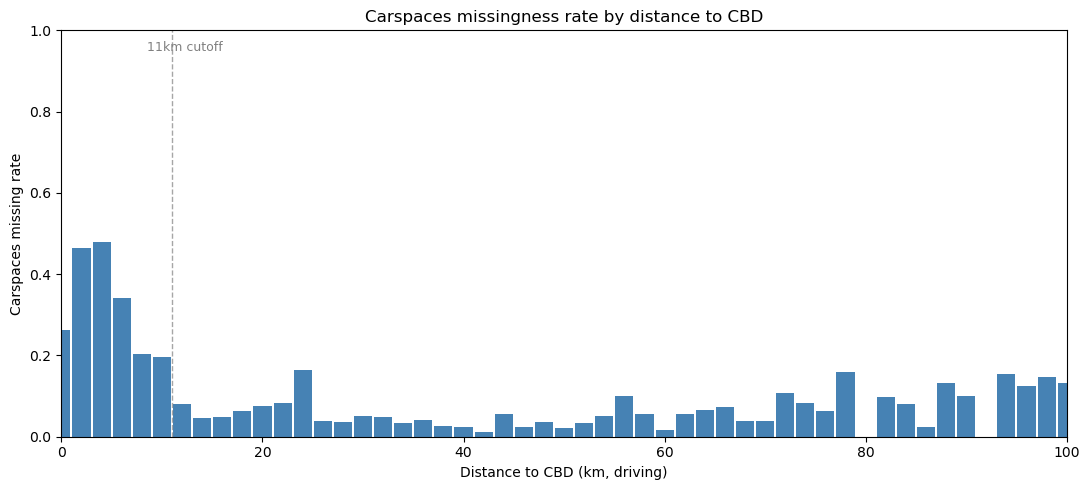

In [87]:
import matplotlib.pyplot as plt

plot_pdf = missing_by_bucket.toPandas()

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(plot_pdf["dist_bucket"], plot_pdf["missing_rate"],
       width=bin_width * 0.9, color="steelblue")

ax.axvline(11, color="grey", ls="--", lw=1, alpha=0.7)
ax.text(8.5, 0.95, "11km cutoff", fontsize=9, color="grey")

ax.set_xlabel("Distance to CBD (km, driving)")
ax.set_ylabel("Carspaces missing rate")
ax.set_ylim(0, 1)
ax.set_xlim(0, 100) # only looking at majority of listings here - outside is not reliable
ax.set_title("Carspaces missingness rate by distance to CBD")

fig.tight_layout()
plt.show()

Based on the plot, missingness is heavily concentrated within roughly 11km of the CBD. Define an inner-city subset at that cutoff and re-check the missing rate within it.

In [88]:
df_inner = df_curated_two.filter(F.col("dist_to_cbd_km_driving") < 11)

n_total_inner = df_inner.count()
n_missing_inner = df_inner.filter(F.col("carspaces").isNull()).count()

print(f"Inner-city (<11km) properties: {n_total_inner:,}")
print(f"Missing carspaces: {n_missing_inner:,} / {n_total_inner:,} "
      f"({100 * n_missing_inner / n_total_inner:.2f}%)")

Inner-city (<11km) properties: 2,907
Missing carspaces: 1,049 / 2,907 (36.09%)


Break inner-city missingness down by `property_type`, to confirm it's still concentrated in apartments/studios once we've already conditioned on being central.

In [89]:
df_inner.filter(F.col("carspaces").isNull()) \
    .groupBy("property_type") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(20, truncate=False)

+-----------------------------+-----+
|property_type                |count|
+-----------------------------+-----+
|Apartment / Unit / Flat      |807  |
|House                        |145  |
|Studio                       |73   |
|Townhouse                    |9    |
|New Apartments / Off the Plan|9    |
|Semi-Detached                |2    |
|Block of Units               |2    |
|Terrace                      |2    |
+-----------------------------+-----+



Check the `carspaces` distribution among inner-city listings that *do* report a value — if `0` never appears here, that supports treating missing as a genuine structural zero rather than an unknown value.

In [90]:
df_inner.filter(
    F.col("carspaces").isNotNull()
).groupBy("carspaces").count().orderBy("carspaces").show()

+---------+-----+
|carspaces|count|
+---------+-----+
|      1.0| 1565|
|      2.0|  260|
|      3.0|   21|
|      4.0|    9|
|      5.0|    2|
|      9.0|    1|
+---------+-----+



No inner-city listing (regardless of property type, including Houses) ever reports 0 explicit car spaces, consistent with agents omitting the field rather than recording zero. Impute 0 for all missing `carspaces` within 11km.

In [91]:
# --- Impute 0 car spaces for inner-city (<11km) properties ---
condition = (
    F.col("carspaces").isNull() &
    (F.col("dist_to_cbd_km_driving") < 11)
)

n_before = df_curated_two.filter(condition).count()

df_curated_two = df_curated_two.withColumn(
    "carspaces",
    F.when(condition, F.lit(0)).otherwise(F.col("carspaces"))
)

n_after = df_curated_two.filter(
    F.col("carspaces").isNull() &
    (F.col("dist_to_cbd_km_driving") < 11)
).count()

print(f"Imputed 0 carspaces for {n_before - n_after:,} inner-city listings")
print(f"Remaining nulls in scope: {n_after:,}")

Imputed 0 carspaces for 1,049 inner-city listings
Remaining nulls in scope: 0


### Beyond 11km
Check whether the same missingness pattern holds for listings further from the CBD, where car spaces are typically less scarce.

In [92]:
df_outer = df_curated_two.filter(F.col("dist_to_cbd_km_driving") >= 11)

n_total_outer = df_outer.count()
n_missing_outer = df_outer.filter(F.col("carspaces").isNull()).count()

print(f"Outer (>=11km) properties: {n_total_outer:,}")
print(f"Missing carspaces: {n_missing_outer:,} / {n_total_outer:,} "
      f"({100 * n_missing_outer / n_total_outer:.2f}%)")

Outer (>=11km) properties: 9,410
Missing carspaces: 655 / 9,410 (6.96%)


Compare each property type's missing rate against the outer-suburb overall rate, to see which types (if any) still stand out.

In [93]:
from pyspark.sql import functions as F

# Overall missingness rate
total_stats = df_outer.agg(
    F.count("*").alias("total_count"),
    F.sum(
        F.when(F.col("carspaces").isNull(), 1).otherwise(0)
    ).alias("missing_count")
).collect()[0]

overall_missing_rate = (
    total_stats["missing_count"] / total_stats["total_count"] * 100
)

# Missingness rate by property type
comparison = df_outer.groupBy("property_type") \
    .agg(
        F.count("*").alias("total_count"),
        F.sum(
            F.when(F.col("carspaces").isNull(), 1).otherwise(0)
        ).alias("missing_count")
    ) \
    .withColumn(
        "missing_rate_pct",
        F.col("missing_count") / F.col("total_count") * 100
    ) \
    .withColumn(
        "overall_missing_rate_pct",
        F.lit(overall_missing_rate)
    ) \
    .withColumn(
        "difference_pp",
        F.col("missing_rate_pct") -
        F.col("overall_missing_rate_pct")
    ) \
    .orderBy(F.desc("missing_rate_pct"))

comparison.show(truncate=False)

+-----------------------------+-----------+-------------+------------------+------------------------+-------------------+
|property_type                |total_count|missing_count|missing_rate_pct  |overall_missing_rate_pct|difference_pp      |
+-----------------------------+-----------+-------------+------------------+------------------------+-------------------+
|New Apartments / Off the Plan|35         |31           |88.57142857142857 |6.9606801275239105      |81.61074844390465  |
|Studio                       |107        |74           |69.1588785046729  |6.9606801275239105      |62.19819837714899  |
|Farm                         |2          |1            |50.0              |6.9606801275239105      |43.03931987247609  |
|Semi-Detached                |5          |1            |20.0              |6.9606801275239105      |13.039319872476089 |
|Acreage / Semi-Rural         |11         |2            |18.181818181818183|6.9606801275239105      |11.221138054294272 |
|New House & Land       

Repeat the rent/bedrooms/bathrooms/days_listed comparison for the outer subset, to check whether the same MNAR-style gap is present out here.

In [94]:
df_outer.withColumn("carspaces_missing", F.col("carspaces").isNull()) \
    .groupBy("carspaces_missing") \
    .agg(
        F.round(F.mean("weekly_rent"), 2).alias("mean_rent"),
        F.round(F.mean("bedrooms"), 2).alias("mean_bedrooms"),
        F.round(F.mean("bathrooms"), 2).alias("mean_bathrooms"),
        F.round(F.mean("days_listed"), 2).alias("mean_days_listed"),
        F.count("*").alias("n"),
    ) \
    .orderBy(F.desc("n")) \
    .show(50, truncate=False)

+-----------------+---------+-------------+--------------+----------------+----+
|carspaces_missing|mean_rent|mean_bedrooms|mean_bathrooms|mean_days_listed|n   |
+-----------------+---------+-------------+--------------+----------------+----+
|false            |604.27   |3.06         |1.69          |44.72           |8755|
|true             |476.79   |2.06         |1.25          |136.61          |655 |
+-----------------+---------+-------------+--------------+----------------+----+



`Studio`, `New Apartments / Off the Plan`, and `Apartment / Unit / Flat` all sit above the outer-suburb baseline missing rate. Impute 0 for missing `carspaces` across all three, beyond 11km.

In [95]:
# --- Impute 0 car spaces for outer (>=11km) Studio / New Apartments / Apartment listings ---
target_types = ["Studio", "New Apartments / Off the Plan", 
                "Apartment / Unit / Flat"]

condition = (
    F.col("property_type").isin(target_types) &
    F.col("carspaces").isNull() &
    (F.col("dist_to_cbd_km_driving") >= 11)
)

n_before = df_curated_two.filter(condition).count()

df_curated_two = df_curated_two.withColumn(
    "carspaces",
    F.when(condition, F.lit(0)).otherwise(F.col("carspaces"))
)

n_after = df_curated_two.filter(
    F.col("property_type").isin(target_types) &
    F.col("carspaces").isNull() &
    (F.col("dist_to_cbd_km_driving") >= 11)
).count()

print(f"Imputed 0 carspaces for {n_before - n_after:,} outer (>=11km) "
      f"Studio/New Apartments/Apartment listings")
print(f"Remaining nulls in scope: {n_after:,}")

Imputed 0 carspaces for 292 outer (>=11km) Studio/New Apartments/Apartment listings
Remaining nulls in scope: 0


Re-check the missing/non-missing comparison across the whole dataset after both rounds of 0-imputation — the gap should have narrowed if the structural-zero cases have been resolved.

In [96]:
df_curated_two.withColumn(
    "carspaces_missing", F.col("carspaces").isNull()
).groupBy("carspaces_missing").agg(
    F.round(F.mean("weekly_rent"), 2).alias("mean_rent"),
    F.round(F.mean("bedrooms"), 2).alias("mean_bedrooms"),
    F.round(F.mean("bathrooms"), 2).alias("mean_bathrooms"),
    F.round(F.mean("days_listed"), 2).alias("mean_days_listed"),
    F.count("*").alias("n"),
).orderBy("carspaces_missing").show(truncate=False)

+-----------------+---------+-------------+--------------+----------------+-----+
|carspaces_missing|mean_rent|mean_bedrooms|mean_bathrooms|mean_days_listed|n    |
+-----------------+---------+-------------+--------------+----------------+-----+
|false            |634.17   |2.72         |1.59          |56.39           |11954|
|true             |524.46   |2.67         |1.36          |88.13           |363  |
+-----------------+---------+-------------+--------------+----------------+-----+



### Group-based median imputation for the remainder
The remaining nulls (mostly `House`, plus several small categories) show no clear structural-zero evidence — this looks like ordinary MAR. To avoid unstable medians from tiny categories (e.g. `Farm`, n=1-2), group similar `property_type`s together.

In [97]:
property_group_map = {
    "House": "House-like",
    "New House & Land": "House-like",
    "Acreage / Semi-Rural": "House-like",
    "Farm": "House-like",

    "Apartment / Unit / Flat": "Apartment-like",
    "Studio": "Apartment-like",
    "New Apartments / Off the Plan": "Apartment-like",
    "Block of Units": "Apartment-like",

    "Townhouse": "Attached-like",
    "Duplex": "Attached-like",
    "Semi-Detached": "Attached-like",
    "Terrace": "Attached-like",
    "Villa": "Attached-like",
}

mapping_expr = F.create_map(*[
    x for k, v in property_group_map.items() for x in (F.lit(k), F.lit(v))
])

df_curated_two = df_curated_two.withColumn(
    "property_group", mapping_expr[F.col("property_type")]
)

df_curated_two.groupBy("property_group").count().orderBy(F.desc("count")).show()

+--------------+-----+
|property_group|count|
+--------------+-----+
|    House-like| 6369|
|Apartment-like| 4655|
| Attached-like| 1293|
+--------------+-----+



Bucket `dist_to_cbd_km_driving` into exponentially widening bands — finer near the CBD, coarser further out — to capture the same distance effect without splitting the data too thin.

In [98]:
# Exponential bin edges: fine-grained near the CBD, coarse further out
dist_bin_edges = [0, 2, 4, 8, 16, 32, 64, 128, 600]

bucket_expr = F.lit(None)
for i in range(len(dist_bin_edges) - 1):
    lower, upper = dist_bin_edges[i], dist_bin_edges[i + 1]
    label = f"{lower}-{upper}km"
    bucket_expr = F.when(
        (F.col("dist_to_cbd_km_driving") >= lower) & (F.col("dist_to_cbd_km_driving") < upper),
        F.lit(label)
    ).otherwise(bucket_expr)

df_curated_two = df_curated_two.withColumn("dist_bucket_exp", bucket_expr)

df_curated_two.groupBy("dist_bucket_exp").count().orderBy("dist_bucket_exp").show(20, truncate=False)

+---------------+-----+
|dist_bucket_exp|count|
+---------------+-----+
|0-2km          |114  |
|128-600km      |1070 |
|16-32km        |3070 |
|2-4km          |533  |
|32-64km        |2960 |
|4-8km          |1364 |
|64-128km       |1060 |
|8-16km         |2146 |
+---------------+-----+



Impute remaining nulls using the median `carspaces` for each `(property_group, distance_bucket)` combination, provided it has at least 15 non-null observations; otherwise fall back to the `property_group`-level median.

In [99]:
# --- Median imputation for remaining carspaces nulls, by property_group + distance bucket ---
MIN_GROUP_SIZE = 15  # minimum non-null count before trusting the fine-grained median

# Fine-grained medians: property_group x dist_bucket_exp
fine_medians = (
    df_curated_two.filter(F.col("carspaces").isNotNull())
    .groupBy("property_group", "dist_bucket_exp")
    .agg(
        F.expr("percentile_approx(carspaces, 0.5)").alias("median_carspaces"),
        F.count("*").alias("n"),
    )
    .filter(F.col("n") >= MIN_GROUP_SIZE)
    .collect()
)
fine_lookup = {
    (r["property_group"], r["dist_bucket_exp"]): int(round(r["median_carspaces"]))
    for r in fine_medians
}

# Coarse fallback: property_group only
coarse_medians = (
    df_curated_two.filter(F.col("carspaces").isNotNull())
    .groupBy("property_group")
    .agg(F.expr("percentile_approx(carspaces, 0.5)").alias("median_carspaces"))
    .collect()
)
coarse_lookup = {r["property_group"]: int(round(r["median_carspaces"])) for r in coarse_medians}

# Final fallback: overall median
overall_median = int(round(
    df_curated_two.filter(F.col("carspaces").isNotNull())
    .approxQuantile("carspaces", [0.5], 0.0)[0]
))

print(f"Fine-grained groups computed: {len(fine_lookup)}")
print(f"Coarse (property_group) fallbacks: {coarse_lookup}")
print(f"Overall median fallback: {overall_median}")
print(f"Total NULL carspaces before: "
      f"{df_curated_two.filter(F.col('carspaces').isNull()).count()}")
print()

# Build fine-grained lookup as a small Spark DataFrame and join it in
fine_rows = [(pg, db, val) for (pg, db), val in fine_lookup.items()]
fine_lookup_sdf = spark.createDataFrame(
    fine_rows, ["property_group", "dist_bucket_exp", "fine_median"]
)

df_curated_two = df_curated_two.join(
    fine_lookup_sdf, on=["property_group", "dist_bucket_exp"], how="left"
)

coarse_map_expr = F.create_map(*[
    x for pg, val in coarse_lookup.items() for x in (F.lit(pg), F.lit(val))
])
df_curated_two = df_curated_two.withColumn(
    "coarse_median", coarse_map_expr[F.col("property_group")]
)

df_curated_two = df_curated_two.withColumn(
    "carspaces",
    F.when(
        F.col("carspaces").isNull(),
        F.coalesce(F.col("fine_median"), F.col("coarse_median"), F.lit(overall_median))
    ).otherwise(F.col("carspaces"))
).drop("fine_median", "coarse_median")

print(f"Total NULL carspaces after: "
      f"{df_curated_two.filter(F.col('carspaces').isNull()).count()}")

Fine-grained groups computed: 23
Coarse (property_group) fallbacks: {'Attached-like': 2, 'House-like': 2, 'Apartment-like': 1}
Overall median fallback: 1
Total NULL carspaces before: 363

Total NULL carspaces after: 0


# Save the cleaned DataFrame to Parquet format


In [100]:
output_path = "../../rea_data/curated/vic_rentals_curated_3.parquet"

df_curated_two.write.mode("overwrite").parquet(output_path)

print(f"Shape: {df_curated_two.count():,} rows, {len(df_curated_two.columns)} columns")

Shape: 12,317 rows, 89 columns


<br>
<br>
<br>

### Dealing with `property_type`

Finally, lets ensure we clean the `property_type` column as this is another important column we will use during analysis.

In [108]:
curated_three_path = "../../rea_data/curated/vic_rentals_curated_3.parquet"

df_curated_three = spark.read.parquet(curated_three_path)

In [109]:
null_check(df_curated_three)

Total rows: 12,317
Rows with at least one null value: 12,317
Percentage of rows with atleast one NULL: 100.0%

property_group                       0
dist_bucket_exp                      0
lat                                  0
lon                                  0
listing_id                           0
suburb                               0
postcode                             0
weekly_rent                          0
bond                               734
available_date                       0
date_listed                          0
days_listed                          0
bedrooms                             0
bathrooms                            0
carspaces                            0
property_type                        0
address                             83
scraped_date                         0
domain_page_id                       0
property_id                      9,999
photo_count                          0
video_count                          0
floorplans_count               

As per the `NULL` check above, there are no `NULL` `property_type`'s to impute which is good. Lets also make sure there are there are no blank strings.

In [110]:
# Check property_type for blank or placeholder values missed by null_check
PLACEHOLDERS = ["unknown", "n/a", "na", "none", "null", "-", "-", '""', "''"]

trimmed_type = F.trim(F.col("property_type"))

df_curated_three.select(
    F.sum(F.col("property_type").isNull().cast("int")).alias("null"),
    F.sum((trimmed_type == "").cast("int")).alias("empty_or_whitespace"),
    F.sum(
        F.lower(trimmed_type).isin(PLACEHOLDERS).cast("int")
    ).alias("placeholder"),
).show()

+----+-------------------+-----------+
|null|empty_or_whitespace|placeholder|
+----+-------------------+-----------+
|   0|                  0|          0|
+----+-------------------+-----------+



In [111]:
# List every distinct property_type with its listing count
df_curated_three.groupBy("property_type") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(50, truncate=False)

+-----------------------------+-----+
|property_type                |count|
+-----------------------------+-----+
|House                        |6349 |
|Apartment / Unit / Flat      |4416 |
|Townhouse                    |1251 |
|Studio                       |192  |
|New Apartments / Off the Plan|44   |
|Villa                        |26   |
|Acreage / Semi-Rural         |11   |
|Semi-Detached                |10   |
|New House & Land             |7    |
|Block of Units               |3    |
|Terrace                      |3    |
|Duplex                       |3    |
|Farm                         |2    |
+-----------------------------+-----+



Evidently, every property type is fine. This column is clean.

<br>
<br>
<br>

### Completion of Data Cleaning

The final step in our data cleaning process is to drop every column that is no use to us anymore

In [112]:
df_curated_three.printSchema()

root
 |-- property_group: string (nullable = true)
 |-- dist_bucket_exp: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- listing_id: string (nullable = true)
 |-- suburb: string (nullable = true)
 |-- postcode: string (nullable = true)
 |-- weekly_rent: double (nullable = true)
 |-- bond: double (nullable = true)
 |-- available_date: string (nullable = true)
 |-- date_listed: date (nullable = true)
 |-- days_listed: double (nullable = true)
 |-- bedrooms: double (nullable = true)
 |-- bathrooms: double (nullable = true)
 |-- carspaces: double (nullable = true)
 |-- property_type: string (nullable = true)
 |-- address: string (nullable = true)
 |-- scraped_date: timestamp (nullable = true)
 |-- domain_page_id: string (nullable = true)
 |-- property_id: string (nullable = true)
 |-- photo_count: integer (nullable = true)
 |-- video_count: integer (nullable = true)
 |-- floorplans_count: integer (nullable = true)
 |-- virtual_tour: boole

In [113]:
# Drop columns not needed for modelling
COLS_TO_DROP = [
    "property_group",
    "dist_bucket_exp",
    "postcode",
    "bond",
    "available_date",
    "days_listed",
    "address",
    "scraped_date",
    "domain_page_id",
    "property_id",
    "photo_count",
    "video_count",
    "floorplans_count",
    "virtual_tour",
    "primary_type",
    "secondary_type",
    "agency",
    "agency_id",
    "agent_names",
    "structured_features",
    "url",
    "land_area",
    "land_area_sqm",
    "energy_eff_rating",
]

# Catch typos: Spark's drop() silently ignores names that don't exist
missing = [c for c in COLS_TO_DROP if c not in df_curated_three.columns]
if missing:
    print(f"Not found (check spelling): {missing}")

n_cols_before = len(df_curated_three.columns)
df_curated_three = df_curated_three.drop(*COLS_TO_DROP)

print(f"Columns: {n_cols_before} -> {len(df_curated_three.columns)}")
df_curated_three.printSchema()

Columns: 89 -> 65
root
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- listing_id: string (nullable = true)
 |-- suburb: string (nullable = true)
 |-- weekly_rent: double (nullable = true)
 |-- date_listed: date (nullable = true)
 |-- bedrooms: double (nullable = true)
 |-- bathrooms: double (nullable = true)
 |-- carspaces: double (nullable = true)
 |-- property_type: string (nullable = true)
 |-- feat_built_in_wardrobes: integer (nullable = true)
 |-- feat_heating: integer (nullable = true)
 |-- feat_dishwasher: integer (nullable = true)
 |-- feat_secure_parking: integer (nullable = true)
 |-- feat_internal_laundry: integer (nullable = true)
 |-- feat_air_conditioning: integer (nullable = true)
 |-- feat_balcony___deck: integer (nullable = true)
 |-- feat_gas: integer (nullable = true)
 |-- feat_floorboards: integer (nullable = true)
 |-- feat_bath: integer (nullable = true)
 |-- feat_intercom: integer (nullable = true)
 |-- feat_ensuite: integer (nullable 